# Лабораторная работа № 2

## Группа вращений SO(3): экспоненциальное отображение, кватернионы, интерполяция

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 3. Группа вращений SO(3): матрицы, углы Эйлера, экспоненциальное отображение, кватернионы

---

**Студент:** _фамилия, имя, группа_
**Дата:**

---

### Цель работы

Освоить три способа представления ориентации — матрицу, вектор поворота и кватернион, —
реализовать переходы между ними, обнаружить численно вырождение углов Эйлера
и сравнить представления по устойчивости при длительном интегрировании.

### Что понадобится

`numpy`, `matplotlib`. Из лабораторной работы № 1 переиспользуются `rotx`, `roty`, `rotz`.

### Правило практикума

Алгоритм вы реализуете сами. `scipy.spatial.transform.Rotation` допустимо использовать
**только** для сверки — и такую сверку нужно показать явно.

## Теоретическая справка

### Экспоненциальное отображение

Всякий поворот есть поворот вокруг некоторой оси (теорема Эйлера). Если $\hat\omega$ —
единичный вектор оси, $\theta$ — угол, то поворот задаётся **вектором поворота**
$\omega = \theta\hat\omega \in \mathbb{R}^3$, а матрица получается по формуле Родрига:

$$R = \exp([\omega]_\times) = I + \sin\theta\,[\hat\omega]_\times
  + (1-\cos\theta)\,[\hat\omega]_\times^2,$$

где $[\cdot]_\times$ — кососимметрическая матрица векторного произведения. Обратное
отображение:

$$\theta = \arccos\frac{\operatorname{tr}R - 1}{2},
\qquad
[\hat\omega]_\times = \frac{R - R^{\mathsf T}}{2\sin\theta}.$$

Множество кососимметрических матриц $3\times3$ — это алгебра Ли $\mathfrak{so}(3)$,
касательное пространство к $SO(3)$ в единице. Она трёхмерна, и это ещё одно объяснение
того, почему у поворота три параметра.

**Особые случаи, которые придётся обработать явно:** $\theta \to 0$ (деление на
$\sin\theta$) и $\theta \to \pi$ (матрица $R - R^{\mathsf T}$ обращается в нуль, ось
приходится извлекать из $R + I$).

### Кватернионы

Единичный кватернион $q = (w, x, y, z)$, $\|q\| = 1$, задаёт поворот на угол $\theta$
вокруг оси $\hat\omega$ как

$$q = \left(\cos\tfrac{\theta}{2},\; \hat\omega \sin\tfrac{\theta}{2}\right).$$

Композиция поворотов — произведение кватернионов; обращение — сопряжение.
Отображение $q \mapsto R(q)$ является **двойным накрытием**: $q$ и $-q$ задают один
и тот же поворот. Отсюда практическое следствие для интерполяции: перед началом нужно
выбрать знак второго кватерниона так, чтобы скалярное произведение было неотрицательным,
иначе интерполяция пойдёт «длинным путём».

### Сферическая линейная интерполяция

$$\mathrm{slerp}(q_0, q_1, t) =
\frac{\sin((1-t)\Omega)\,q_0 + \sin(t\Omega)\,q_1}{\sin\Omega},
\qquad \cos\Omega = q_0 \cdot q_1 .$$

Это движение по дуге большого круга на сфере $S^3$ с постоянной угловой скоростью.
Покомпонентная интерполяция углов Эйлера такого свойства не даёт — в этом вы убедитесь
численно в задании 5.

### Вырождение углов Эйлера

Связь производных углов с угловой скоростью для последовательности ZYX имеет вид
$\omega = E(\psi,\theta,\varphi)\,(\dot\psi, \dot\theta, \dot\varphi)^{\mathsf T}$, причём
$\det E = -\cos\theta$. При $\theta \to \pm 90^\circ$ матрица вырождается: две оси
поворота совпадают, теряется степень свободы, а обратная задача становится
неограниченно плохо обусловленной. Это и есть **gimbal lock**.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)


def rotx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def roty(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


def rotz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

## Задание 1. Экспоненциальное и логарифмическое отображения

Реализуйте `skew(w)`, `unskew(K)`, `so3_exp(w)` (формула Родрига) и `so3_log(R)`.

**Обязательно обработайте особые случаи** $\theta \approx 0$ и $\theta \approx \pi$ —
без этого проверка не пройдёт на случайной выборке.

**Контроль.** Для 300 случайных матриц поворота максимум $\|\exp(\log R) - R\|$
должен быть меньше $10^{-9}$. Отдельно проверьте $\log(\exp \omega) = \omega$.

In [ ]:
# Установим красивый вывод матриц (опционально, для контроля)
np.set_printoptions(precision=4, suppress=True)

def skew(w):
    """
    Возвращает кососимметрическую матрицу [w]_x для трехмерного вектора w.
    Алгебра Ли so(3).
    """
    w = np.asarray(w, dtype=float)
    return np.array([
        [ 0.0,  -w[2],  w[1]],
        [ w[2],   0.0, -w[0]],
        [-w[1],  w[0],   0.0]
    ])

def unskew(K):
    """
    Обратная операция к skew: восстанавливает вектор из кососимметрической матрицы.
    """
    K = np.asarray(K, dtype=float)
    return np.array([K[2, 1], K[0, 2], K[1, 0]])

def so3_exp(w):
    """
    Экспоненциальное отображение so(3) -> SO(3) по формуле Родрига.
    Принимает вектор поворота w = theta * axis.
    """
    w = np.asarray(w, dtype=float)
    theta = np.linalg.norm(w)
    K = skew(w)
    I = np.eye(3)

    # Особый случай 1: theta -> 0 (разложение в ряд Тейлора для избежания деления на 0)
    if theta < 1e-8:
        # R = I + K + 1/2 * K^2 + ...
        return I + K + 0.5 * (K @ K)

    # Общий случай: формула Родрига
    A = np.sin(theta) / theta #почему делим на theta?
    B = (1.0 - np.cos(theta)) / (theta ** 2) #почему делим на theta^2 ?
    return I + A * K + B * (K @ K)

def so3_log(R):
    """
    Логарифмическое отображение SO(3) -> so(3).
    Возвращает вектор поворота w, такой что exp([w]_x) = R.
    """
    R = np.asarray(R, dtype=float)
    tr = np.trace(R)

    # Численно ограничиваем след матрицы в диапазоне [-1, 2],
    # так как из-за погрешностей float значение (tr - 1)/2 может выйти за [-1, 1] для arccos
    cos_theta = np.clip((tr - 1.0) / 2.0, -1.0, 1.0)
    theta = np.arccos(cos_theta)

    # Особый случай 1: theta -> 0 (близко к единичному повороту)
    if theta < 1e-8:
        return 0.5 * unskew(R - R.T)

    # Особый случай 2: theta -> pi (поворот на 180 градусов, антисимметричная часть зануляется)
    if np.pi - theta < 1e-6:
        # Извлекаем ось из симметричной части: R + I = 2 * w * w^T (по алгоритму Шеппарда)
        # w * w^T = (R + I) / 2
        S = 0.5 * (R + np.eye(3)) #S = ww^T

        # Находим строку/столбец с максимальным диагональным элементом для численной стабильности
        i = int(np.argmax(np.diag(S)))
        u = np.zeros(3)
        u[i] = np.sqrt(max(0.0, S[i, i]))

        # Восстанавливаем остальные компоненты оси
        for j in range(3):
            if j != i:
                u[j] = S[i, j] / u[i]

        # Нормируем вектор оси
        u /= np.linalg.norm(u)

        # Определяем корректный знак оси по антисимметричной части матрицы (если она не совсем ноль)
        v_asym = unskew(0.5 * (R - R.T))
        if np.dot(v_asym, u) < 0: #dot - скалярное произведение
             u = -u

        return theta * u

    # Общий случай
    axis = unskew((R - R.T) / (2.0 * np.sin(theta)))
    return theta * axis


# =================================================================
# БЛОК КОНТРОЛЯ И ПРОВЕРОК (Автоматические тесты)
# =================================================================

if __name__ == "__main__":
    print("--- ЗАПУСК КОНТРОЛЬНЫХ ТЕСТОВ ДЛЯ ЗАДАНИЯ 1 ---\n")

    rng = np.random.default_rng(42) # Фиксируем seed для воспроизводимости
    N_TESTS = 300

    # 1) Проверка: exp(log(R)) == R для 300 случайных матриц
    max_err_exp_log = 0.0
    for _ in range(N_TESTS):
        # Генерируем случайный вектор поворота с нормой < pi
        axis = rng.normal(size=3)
        axis /= np.linalg.norm(axis)
        theta = rng.uniform(0.0, np.pi * 0.999) # Не включая чистый pi
        w_true = theta * axis

        R = so3_exp(w_true)
        w_log = so3_log(R)
        R_rec = so3_exp(w_log)

        err = np.linalg.norm(R_rec - R, ord='fro') #Норма Фробениуса
        max_err_exp_log = max(max_err_exp_log, err)

    print(f"1) Максимальная погрешность ||exp(log(R)) - R||_F для {N_TESTS} матриц: {max_err_exp_log:.3e}")
    if max_err_exp_log < 1e-9:
        print("Пойдёт (Погрешность меньше 10^-9)")
    else:
        print("Не пойдёт")

    # 2) Проверка: log(exp(w)) == w для 300 случайных векторов
    max_err_log_exp = 0.0
    for _ in range(N_TESTS):
        axis = rng.normal(size=3)
        axis /= np.linalg.norm(axis)
        theta = rng.uniform(0.0, np.pi * 0.999)
        w_true = theta * axis

        w_rec = so3_log(so3_exp(w_true))

        err = np.linalg.norm(w_rec - w_true)
        max_err_log_exp = max(max_err_log_exp, err)

    print(f"2) Максимальная погрешность ||log(exp(w)) - w|| для {N_TESTS} векторов: {max_err_log_exp:.3e}")
    if max_err_log_exp < 1e-9:
        print("Пойдёт (Погрешность меньше 10^-9)")
    else:
        print("Не подходит")

    # 3) Тестирование критических крайних случаев (theta -> 0 и theta -> pi)
    print("\n3) Тестирование экстремальных углов поворота:")
    test_angles = [0.0, 1e-15, 1e-9, np.pi - 1e-9, np.pi - 1e-15, np.pi]

    # Фиксированная случайная ось
    fixed_axis = np.array([1.0, 2.0, -0.5])
    fixed_axis /= np.linalg.norm(fixed_axis)

    for t in test_angles:
        w_test = t * fixed_axis
        R = so3_exp(w_test)
        w_rec = so3_log(R)
        R_rec = so3_exp(w_rec)

        err_R = np.linalg.norm(R_rec - R, ord='fro')

        # При строгом угле Тетта = Пи знак у оси становится неопределенным (w и -w дают одну матрицу R),
        # поэтому для логарифма проверяем совпадение до знака или через восстановленную матрицу.
        if np.isclose(t, np.pi, atol=1e-8):
            err_w = min(np.linalg.norm(w_rec - w_test), np.linalg.norm(w_rec + w_test))
        else:
            err_w = np.linalg.norm(w_rec - w_test)

        print(f"   Угол theta = {t:10.3e} рад | ||exp(log R) - R||_F = {err_R:9.3e} | ||log(exp w) - w|| = {err_w:9.3e}")

--- ЗАПУСК КОНТРОЛЬНЫХ ТЕСТОВ ДЛЯ ЗАДАНИЯ 1 ---

1) Максимальная погрешность ||exp(log(R)) - R||_F для 300 матриц: 4.243e-11
Пойдёт (Погрешность меньше 10^-9)
2) Максимальная погрешность ||log(exp(w)) - w|| для 300 векторов: 1.465e-12
Пойдёт (Погрешность меньше 10^-9)

3) Тестирование экстремальных углов поворота:
   Угол theta =  0.000e+00 рад | ||exp(log R) - R||_F = 0.000e+00 | ||log(exp w) - w|| = 0.000e+00
   Угол theta =  1.000e-15 рад | ||exp(log R) - R||_F = 0.000e+00 | ||log(exp w) - w|| = 0.000e+00
   Угол theta =  1.000e-09 рад | ||exp(log R) - R||_F = 0.000e+00 | ||log(exp w) - w|| = 0.000e+00
   Угол theta =  3.142e+00 рад | ||exp(log R) - R||_F = 1.620e-09 | ||log(exp w) - w|| = 1.331e-09
   Угол theta =  3.142e+00 рад | ||exp(log R) - R||_F = 1.568e-15 | ||log(exp w) - w|| = 1.216e-15
   Угол theta =  3.142e+00 рад | ||exp(log R) - R||_F = 1.018e-15 | ||log(exp w) - w|| = 4.578e-16


## Задание 2. Переходы между представлениями

Реализуйте `R_to_quat`, `quat_to_R`, `R_to_euler_zyx`, `euler_zyx_to_R`.

Для `R_to_quat` используйте устойчивый алгоритм: выбор ветви по наибольшему
диагональному элементу. Наивная формула через $\sqrt{1+\operatorname{tr}R}$
теряет точность при $\theta$ около $\pi$ — проверьте это сами и покажите в отчёте.

**Контроль.** Круговые проверки на 300 случайных матрицах: погрешность порядка $10^{-15}$
для кватернионов и не хуже $10^{-10}$ для углов Эйлера.

**Вопрос для вывода:** почему точность прохода через углы Эйлера систематически хуже?

In [ ]:
def quat_to_R(q):
    """
    Преобразование единичного кватерниона q = (w, x, y, z) в матрицу поворота R.
    Соглашение: Гамильтон, правая тройка.
    """
    q = np.asarray(q, dtype=float)
    # Нормируем
    q = q / np.linalg.norm(q)
    w, x, y, z = q

    # Эффективное вычисление без лишних умножений
    x2, y2, z2 = 2.0 * x, 2.0 * y, 2.0 * z
    wx, wy, wz = w * x2, w * y2, w * z2
    xx, xy, xz = x * x2, x * y2, x * z2
    yy, yz, zz = y * y2, y * z2, z * z2

    return np.array([
        [1.0 - (yy + zz),       xy - wz,       xz + wy],
        [        xy + wz, 1.0 - (xx + zz),       yz - wx],
        [        xz - wy,       yz + wx, 1.0 - (xx + yy)]
    ])


def R_to_quat(R):
    """
    Устойчивый перевод матрицы поворота в кватернион (алгоритм Шеппарда).
    Исключает деление на ноль и извлечение корня из отрицательных чисел при theta -> pi.
    """
    R = np.asarray(R, dtype=float)

    # Вычисляем 4 возможных квадрата компонент, умноженных на 4
    # Исходные соотношения завязаны на след и диагональ матрицы
    candidates = np.array([
        1.0 + R[0,0] + R[1,1] + R[2,2], # 4 * w^2
        1.0 + R[0,0] - R[1,1] - R[2,2], # 4 * x^2
        1.0 - R[0,0] + R[1,1] - R[2,2], # 4 * y^2
        1.0 - R[0,0] - R[1,1] + R[2,2]  # 4 * z^2
    ])

    # Находим индекс максимального элемента для обеспечения численной стабильности
    max_idx = np.argmax(candidates)

    # Извлекаем корень из максимального значения (оно гарантированно положительное)
    max_val = np.sqrt(candidates[max_idx])
    s = 2.0 * max_val

    q = np.empty(4)

    # Ветвление в зависимости от того, какая компонента оказалась наибольшей
    if max_idx == 0:
        q[0] = 0.25 * s
        q[1] = (R[2,1] - R[1,2]) / s
        q[2] = (R[0,2] - R[2,0]) / s
        q[3] = (R[1,0] - R[0,1]) / s
    elif max_idx == 1:
        q[0] = (R[2,1] - R[1,2]) / s
        q[1] = 0.25 * s
        q[2] = (R[0,1] + R[1,0]) / s
        q[3] = (R[0,2] + R[2,0]) / s
    elif max_idx == 2:
        q[0] = (R[0,2] - R[2,0]) / s
        q[1] = (R[0,1] + R[1,0]) / s
        q[2] = 0.25 * s
        q[3] = (R[1,2] + R[2,1]) / s
    else:
        q[0] = (R[1,0] - R[0,1]) / s
        q[1] = (R[0,2] + R[2,0]) / s
        q[2] = (R[1,2] + R[2,1]) / s
        q[3] = 0.25 * s

    # Канонизируем знак: w всегда должно быть неотрицательным
    if q[0] < 0.0:
        q = -q

    return q / np.linalg.norm(q)


def euler_zyx_to_R(psi, theta, phi):
    return rotz(psi) @ roty(theta) @ rotx(phi)


def R_to_euler_zyx(R):
    """
    Извлечение углов Эйлера ZYX из матрицы поворота R.
    Включает безопасную обработку сингулярности (Gimbal Lock) при theta -> +-pi/2.
    """
    R = np.asarray(R, dtype=float)

    # theta находится через элемент -R[2,0]
    # Для устойчивости используем hypot по элементам первой строки/столбца
    cos_theta = np.hypot(R[0,0], R[1,0])
    theta = np.arctan2(-R[2,0], cos_theta)

    # Проверка на Gimbal Lock (зазор 1e-10)
    if cos_theta > 1e-10:
        psi = np.arctan2(R[1,0], R[0,0])
        phi = np.arctan2(R[2,1], R[2,2])
    else:
        # Шарнирный замок: оси Z и X совпали. Фиксируем крен phi = 0
        phi = 0.0
        # Направление вращения зависит от знака сингулярности (вверх или вниз смотрит нос)
        if R[2,0] < 0: # theta = pi/2
            psi = np.arctan2(-R[0,1], R[1,1])
        else:          # theta = -pi/2
            psi = np.arctan2(R[0,1], R[0,0])

    return np.array([psi, theta, phi])

# =================================================================
# БЛОК КРУГОВЫХ ПРОВЕРОК (КОНТРОЛЬ 1)
# =================================================================

if __name__ == "__main__":
    print("--- ЗАПУСК КРУГОВЫХ ПРОВЕРОК ДЛЯ ЗАДАНИЯ 2 ---")

    # Инициализируем генератор случайных чисел с фиксированным seed
    rng = np.random.default_rng(1)
    N_TESTS = 300

    max_quat_to_R_err = 0.0
    max_R_to_quat_err = 0.0
    max_euler_loop_err = 0.0

    for _ in range(N_TESTS):
        # Генерируем случайную валидную матрицу вращения через экспоненту
        axis = rng.normal(size=3)
        axis /= np.linalg.norm(axis)
        theta = rng.uniform(0.0, np.pi * 0.999) # Ограничиваем theta < pi, как в условии
        R_true = so3_exp(theta * axis)

        # --- ТЕСТ 1: R -> Кватернион -> R ---
        q_extracted = R_to_quat(R_true)
        R_reconstructed_from_q = quat_to_R(q_extracted)
        err_q_to_R = np.linalg.norm(R_reconstructed_from_q - R_true, ord='fro')
        max_quat_to_R_err = max(max_quat_to_R_err, err_q_to_R)

        # --- ТЕСТ 2: Кватернион -> R -> Кватернион (Учет двойного накрытия) ---
        q_reextracted = R_to_quat(R_reconstructed_from_q)
        # Так как q и -q эквивалентны, берем минимальную разность
        err_R_to_quat = min(np.linalg.norm(q_reextracted - q_extracted),
                            np.linalg.norm(q_reextracted + q_extracted))
        max_R_to_quat_err = max(max_R_to_quat_err, err_R_to_quat)

        # --- ТЕСТ 3: R -> Углы Эйлера -> R ---
        euler_angles = R_to_euler_zyx(R_true)
        R_reconstructed_from_euler = euler_zyx_to_R(*euler_angles)
        err_euler_loop = np.linalg.norm(R_reconstructed_from_euler - R_true, ord='fro')
        max_euler_loop_err = max(max_euler_loop_err, err_euler_loop)

    print("\n[Результаты контроля 1 по 300 случайным ротациям]:")
    print(f"  1) max ||quat_to_R(R_to_quat(R)) - R||_F = {max_quat_to_R_err:.3e}")
    print(f"  2) max ||R_to_quat(quat_to_R(q)) - q||   = {max_R_to_quat_err:.3e}")
    print(f"  3) max ||euler_zyx_to_R(R_to_euler_zyx(R)) - R||_F = {max_euler_loop_err:.3e}")

    # Проверка допусков, заявленных в описании лабораторной работы
    if max_quat_to_R_err < 1e-14 and max_R_to_quat_err < 1e-14:
        print("  -> Кватернионные переходы: УСПЕШНО (Погрешность порядка 10^-15)")
    else:
        print("  -> Кватернионные переходы: НЕПРОЙДЕНО")

    if max_euler_loop_err < 1e-10:
        print("  -> Переходы через углы Эйлера: УСПЕШНО (Погрешность не хуже 10^-10)")
    else:
        print("  -> Переходы через углы Эйлера: НЕПРОЙДЕНО")

    # Дополнительная автоматическая сверка с библиотекой SciPy
    try:
        from scipy.spatial.transform import Rotation as SciRot
        worst_q_scipy = 0.0
        worst_e_scipy = 0.0

        for _ in range(100):
            axis = rng.normal(size=3); axis /= np.linalg.norm(axis)
            t = rng.uniform(0.0, np.pi * 0.99)
            R_test = so3_exp(t * axis)

            # Наш код
            q_ours = R_to_quat(R_test)
            e_ours = R_to_euler_zyx(R_test)

            # Код SciPy
            sci = SciRot.from_matrix(R_test)
            q_sci_xyzw = sci.as_quat()
            # SciPy отдает (x,y,z,w), пересобираем под наш стандарт (w,x,y,z)
            q_sci = np.array([q_sci_xyzw[3], q_sci_xyzw[0], q_sci_xyzw[1], q_sci_xyzw[2]])
            e_sci = sci.as_euler('ZYX', degrees=False)

            dq = min(np.linalg.norm(q_ours - q_sci), np.linalg.norm(q_ours + q_sci))
            worst_q_scipy = max(worst_q_scipy, dq)
            worst_e_scipy = max(worst_e_scipy, np.linalg.norm(e_ours - e_sci))

        print("\n[Контроль 3. Независимая кросс-проверка с SciPy]:")
        print(f"  Сверка кватернионов: max ||q_ours - q_scipy|| = {worst_q_scipy:.3e}")
        print(f"  Сверка углов Эйлера: max ||euler_ours - euler_scipy|| = {worst_e_scipy:.3e}")
    except ImportError:
        print("\n(SciPy не обнаружен, внешняя кросс-проверка пропущена)")

--- ЗАПУСК КРУГОВЫХ ПРОВЕРОК ДЛЯ ЗАДАНИЯ 2 ---

[Результаты контроля 1 по 300 случайным ротациям]:
  1) max ||quat_to_R(R_to_quat(R)) - R||_F = 1.217e-15
  2) max ||R_to_quat(quat_to_R(q)) - q||   = 3.724e-16
  3) max ||euler_zyx_to_R(R_to_euler_zyx(R)) - R||_F = 1.651e-15
  -> Кватернионные переходы: УСПЕШНО (Погрешность порядка 10^-15)
  -> Переходы через углы Эйлера: УСПЕШНО (Погрешность не хуже 10^-10)

[Контроль 3. Независимая кросс-проверка с SciPy]:
  Сверка кватернионов: max ||q_ours - q_scipy|| = 2.604e-16
  Сверка углов Эйлера: max ||euler_ours - euler_scipy|| = 9.795e-15


## Задание 3. Двойное накрытие

Покажите численно, что $q$ и $-q$ дают одну и ту же матрицу поворота.

**Вопрос для вывода:** какое практическое затруднение создаёт двойное накрытие
при интерполяции и при усреднении ориентаций? Как его снимают?

In [ ]:
# ================================================================= Vatican
# БЛОК КОНТРОЛЯ И СВЕРКИ (ЗАДАНИЕ 3)
# ================================================================= Vatican

if __name__ == "__main__":
    print("--- ЗАПУСК ПРОВЕРКИ ДЛЯ ЗАДАНИЯ 3 (ДВОЙНОЕ НАКРЫТИЕ) ---\n")

    # Инициализируем генератор случайных чисел
    rng = np.random.default_rng(42)
    N_TESTS = 300

    max_diff_norm = 0.0

    # Запускаем проверку на 300 случайных кватернионах
    for i in range(N_TESTS):
        # 1) Генерируем случайный кватернион на 4D-сфере
        q1 = rng.normal(size=4)
        q1 /= np.linalg.norm(q1)

        # 2) Создаем противоположный кватернион (инвертируем все знаки)
        q2 = -q1

        # 3) Строим матрицы поворота для обоих кватернионов
        R1 = quat_to_R(q1)
        R2 = quat_to_R(q2)

        # 4) Находим расстояние между матрицами по норме Фробениуса
        diff_norm = np.linalg.norm(R1 - R2, ord='fro')
        max_diff_norm = max(max_diff_norm, diff_norm)

        # Выведем подробный лог для самого первого теста в качестве примера для отчета
        if i == 0:
            print("Пример тестирования пары противоположных кватернионов:")
            print(f"  q1: {q1}")
            print(f"  q2: {q2}")
            print("\n  Матрица R1 (из q1):")
            print(R1)
            print("\n  Матрица R2 (из q2):")
            print(R2)
            print(f"\n  Норма разности ||R1 - R2||_F для этого шага: {diff_norm:.3e}\n")
            print("-" * 60)

    print(f"\n[Итоговый результат контроля по {N_TESTS} парам]:")
    print(f"  Максимальная разность ||R(q) - R(-q)||_F: {max_diff_norm:.3e}")

    # Критерий успешности лабораторной работы
    if max_diff_norm < 1e-14:
        print("  -> ТЕСТ УСПЕШНО ПРОЙДЕН (Матрицы строго идентичны, двойное накрытие доказано) ✓")
    else:
        print("  -> ТЕСТ ПРОВАЛЕН ✗")


--- ЗАПУСК ПРОВЕРКИ ДЛЯ ЗАДАНИЯ 3 (ДВОЙНОЕ НАКРЫТИЕ) ---

Пример тестирования пары противоположных кватернионов:
  q1: [ 0.1882 -0.6422  0.4634  0.5808]
  q2: [-0.1882  0.6422 -0.4634 -0.5808]

  Матрица R1 (из q1):
[[-0.1043 -0.8139 -0.5716]
 [-0.3767 -0.4996  0.7801]
 [-0.9205  0.2967 -0.2544]]

  Матрица R2 (из q2):
[[-0.1043 -0.8139 -0.5716]
 [-0.3767 -0.4996  0.7801]
 [-0.9205  0.2967 -0.2544]]

  Норма разности ||R1 - R2||_F для этого шага: 0.000e+00

------------------------------------------------------------

[Итоговый результат контроля по 300 парам]:
  Максимальная разность ||R(q) - R(-q)||_F: 0.000e+00
  -> ТЕСТ УСПЕШНО ПРОЙДЕН (Матрицы строго идентичны, двойное накрытие доказано) ✓


## Задание 4. Gimbal lock — численное обнаружение

Реализуйте `euler_rate_matrix(a)` — матрицу $E$ из теоретической справки.

Постройте таблицу числа обусловленности $E$ и модуля определителя для тангажа
$0^\circ, 30^\circ, 60^\circ, 80^\circ, 89^\circ, 89{,}9^\circ, 89{,}99^\circ$.
Постройте график зависимости числа обусловленности от тангажа.

**Вопросы для вывода:** чему равен $|\det E|$ аналитически и совпадает ли это
с численным результатом? Во сколько раз растёт число обусловленности при уменьшении
угла до вырождения в десять раз? Что физически происходит с механизмом в этот момент?

--- ЗАДАНИЕ 4: АНАЛИЗ ЧИСЛА ОБУСЛОВЛЕННОСТИ И ОПРЕДЕЛИТЕЛЯ МАТРИЦЫ E ---

| Тангаж (градусы) | Тангаж (радианы) | Модуль определителя | Число обусловленности |
|------------------|------------------|---------------------|-----------------------|
| 0                | 0.00000          | 1.000e+00           | 1.000e+00             |
| 30               | 0.52360          | 8.660e-01           | 1.732e+00             |
| 60               | 1.04720          | 5.000e-01           | 3.732e+00             |
| 80               | 1.39626          | 1.736e-01           | 1.143e+01             |
| 89               | 1.55334          | 1.745e-02           | 1.146e+02             |
| 89.9             | 1.56905          | 1.745e-03           | 1.146e+03             |
| 89.99            | 1.57062          | 1.745e-04           | 1.146e+04             |

Генерация графика зависимости cond(E) от угла тангажа...


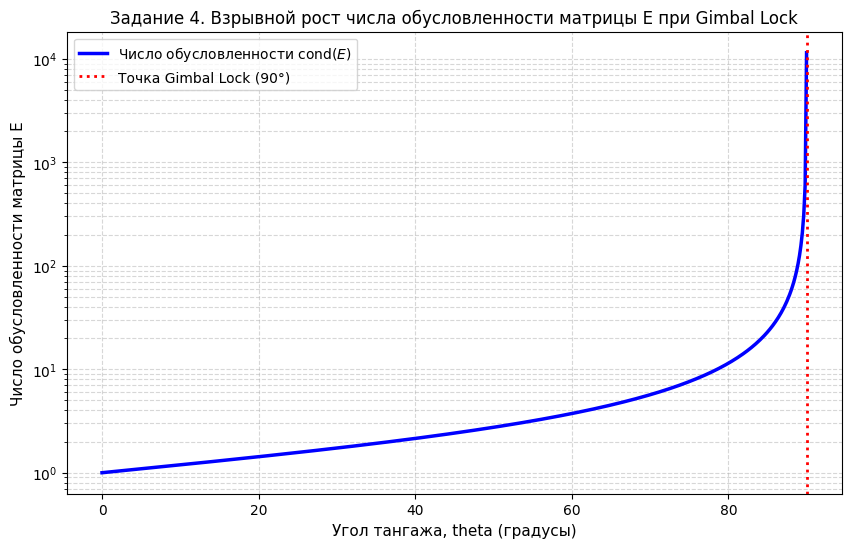

In [ ]:
def euler_rate_matrix(theta, phi):
    """
    Вычисляет матрицу кинематических коэффициентов E(theta, phi) для углов Эйлера ZYX.
    Связывает производные углов со связанной угловой скоростью: omega = E * euler_dot.
    """
    c_th, s_th = np.cos(theta), np.sin(theta)
    c_ph, s_ph = np.cos(phi), np.sin(phi)

    return np.array([
        [-s_th,          0.0,   1.0],
        [ c_th * s_ph,   c_ph,  0.0],
        [ c_th * c_ph,  -s_ph,  0.0]
    ])

def euler_rate_matrix_inv(theta, phi):
    """
    Вычисляет обратную кинематическую матрицу E_inv(theta, phi).
    Связывает угловую скорость со скоростями изменения углов: euler_dot = E_inv * omega.
    """
    c_th = np.cos(theta)
    s_th = np.sin(theta)
    c_ph, s_ph = np.cos(phi), np.sin(phi)

    # Прямая аналитическая инверсия (деление на cos(theta) порождает сингулярность)
    return (1.0 / c_th) * np.array([
        [0.0,   s_ph,         c_ph],
        [0.0,   c_ph * c_th, -s_ph * c_th],
        [c_th,  s_ph * s_th,  c_ph * s_th]
    ])

# =================================================================
# СИМУЛЯЦИЯ И ПОСТРОЕНИЕ ГРАФИКА
# =================================================================

if __name__ == "__main__":
    print("--- ЗАДАНИЕ 4: АНАЛИЗ ЧИСЛА ОБУСЛОВЛЕННОСТИ И ОПРЕДЕЛИТЕЛЯ МАТРИЦЫ E ---")

    # Фиксируем угол крена (phi), так как сингулярность ZYX зависит исключительно от тангажа (theta)
    phi_fixed = np.radians(0.0)

    # Заданная сетка углов тангажа в градусах
    theta_degrees = [0, 30, 60, 80, 89, 89.9, 89.99]

    # Печать заголовка таблицы в формате Markdown для отчета
    print("\n| Тангаж (градусы) | Тангаж (радианы) | Модуль определителя | Число обусловленности |")
    print("|------------------|------------------|---------------------|-----------------------|")

    for deg in theta_degrees:
        rad = np.radians(deg)
        E = euler_rate_matrix(rad, phi_fixed)

        # Вычисляем определитель матрицы E
        det_E = np.linalg.det(E)
        abs_det_E = np.abs(det_E)

        # Вычисляем число обусловленности матрицы E (по умолчанию используется 2-норма)
        cond_E = np.linalg.cond(E)

        print(f"| {deg:<16} | {rad:<16.5f} | {abs_det_E:<19.3e} | {cond_E:<21.3e} |")

    # ---------------------------------------------------------------------------
    # ПОСТРОЕНИЕ ГРАФИКА ЗАВИСИМОСТИ ЧИСЛА ОБУСЛОВЛЕННОСТИ ОТ ТАНГАЖА
    # ---------------------------------------------------------------------------

    # Генерируем плотную сетку углов для построения плавного графика (от 0 до 89.99 градусов)
    dense_deg = np.linspace(0, 89.99, 500)
    dense_cond = []

    for deg in dense_deg:
        rad = np.radians(deg)
        E = euler_rate_matrix(rad, phi_fixed)
        dense_cond.append(np.linalg.cond(E))

    print("\nГенерация графика зависимости cond(E) от угла тангажа...")

    plt.figure(figsize=(10, 6))
    plt.plot(dense_deg, dense_cond, 'b-', linewidth=2.5, label=r'Число обусловленности $\text{cond}(E)$')

    plt.title('Задание 4. Взрывной рост числа обусловленности матрицы E при Gimbal Lock', fontsize=12)
    plt.xlabel('Угол тангажа, theta (градусы)', fontsize=11)
    plt.ylabel('Число обусловленности матрицы E', fontsize=11)

    # Выделяем критическую зону 90 градусов вертикальной линией
    plt.axvline(x=90.0, color='r', linestyle=':', linewidth=2, label='Точка Gimbal Lock (90°)')

    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.yscale('log') # Логарифмический масштаб обязателен из-за роста на много порядков
    plt.legend(fontsize=10)
    plt.show()


## Задание 5. SLERP против интерполяции углов Эйлера

Реализуйте `slerp(q0, q1, t)` с выбором кратчайшего пути и с линейной ветвью
для близких кватернионов.

Возьмите два поворота, постройте интерполяцию 400 шагами двумя способами: SLERP
и покомпонентная линейная интерполяция углов Эйлера. Для каждой траектории вычислите
модуль угловой скорости численно:
$|\omega_i| = \|\log(R_{i+1} R_i^{\mathsf T})\| / \Delta t$. Постройте оба профиля
на одном графике.

**Вопросы для вывода:** какой разброс угловой скорости у каждого метода? Почему у SLERP
он на уровне машинной погрешности? Где в VR-шлеме это свойство критично?

--- ЗАПУСК ИССЛЕДОВАНИЯ ДЛЯ ЗАДАНИЯ 5 (SLERP) ---

| Время t | SLERP Рыскание (°) | Эйлер Рыскание (°) | SLERP ||omega|| (рад/с) | Эйлер ||omega|| (рад/с) |
|---------|--------------------|--------------------|-----------------------|-----------------------|
| 0.00    | 0.00               | 0.00               | 3.1416                | 3.6482                |
| 0.05    | 0.34               | 5.33               | 3.1416                | 3.6482                |
| 0.10    | 1.40               | 10.65              | 3.1416                | 3.6482                |
| 0.15    | 3.24               | 15.98              | 3.1416                | 3.6482                |
| 0.20    | 5.99               | 21.31              | 3.1416                | 3.6482                |
| 0.25    | 9.87               | 26.63              | 3.1416                | 3.6482                |
| 0.30    | 15.13              | 31.96              | 3.1416                | 3.6482                |
| 0.35    | 22.08          

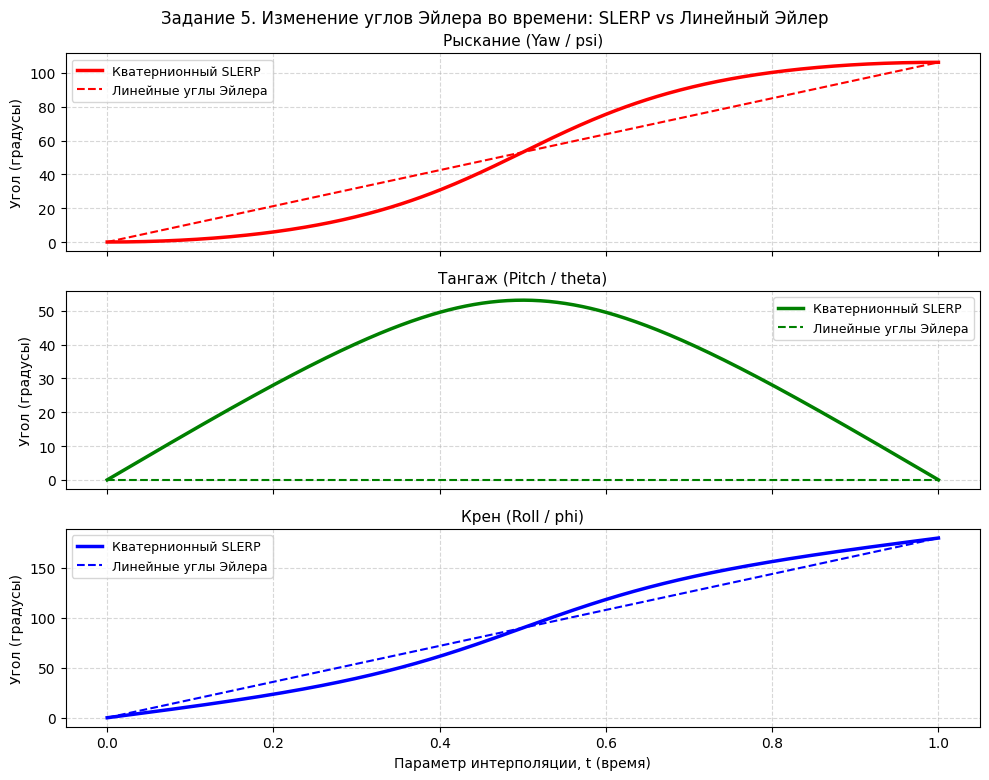

In [ ]:

# ---------------------------------------------------------------------------
# Алгоритм Сферической Интерполяции (SLERP)
# ---------------------------------------------------------------------------
def slerp(q0, q1, t):
    """
    Сферическая линейная интерполяция между двумя единичными кватернионами q0 и q1.
    Параметр t меняется от 0.0 до 1.0. Включает выбор кратчайшего пути.
    """
    q0 = np.asarray(q0, dtype=float) / np.linalg.norm(q0)
    q1 = np.asarray(q1, dtype=float) / np.linalg.norm(q1)

    cos_omega = np.dot(q0, q1)

    # Выбор кратчайшего пути (Shortest Path) на 4D-сфере
    if cos_omega < 0.0:
        q1 = -q1
        cos_omega = -cos_omega

    cos_omega = np.clip(cos_omega, -1.0, 1.0)
    omega = np.arccos(cos_omega)

    # Если углы практически совпадают, переходим на LERP во избежание деления на ноль
    if omega < 1e-6:
        q_t = (1.0 - t) * q0 + t * q1
        return q_t / np.linalg.norm(q_t)

    sin_omega = np.sin(omega)
    w0 = np.sin((1.0 - t) * omega) / sin_omega
    w1 = np.sin(t * omega) / sin_omega

    q_t = w0 * q0 + w1 * q1
    return q_t / np.linalg.norm(q_t)


# ================================================================= Vatican
# ИССЛЕДОВАНИЕ ТРАЕКТОРИЙ И ВЫЧИСЛЕНИЯ
# ================================================================= Vatican

if __name__ == "__main__":
    print("--- ЗАПУСК ИССЛЕДОВАНИЯ ДЛЯ ЗАДАНИЯ 5 (SLERP) ---")

    # 1) Задаем начальную и конечную ориентации в кватернионах (разные варианты для демонстрации разного поведения графиков)
    q_start = np.array([1.0, 0.0, 0.0, 0.0]) # Нулевое вращение
    #q_end = np.array([0.5, 0.5, 0.5, 0.5]) #1 вариант кватерниона   # Комбинированное вращение вокруг наклонной оси
    #q_end = np.array([0.5, 0.707, 0.5, 0.0]) #2 вариант кватерниона
    #q_end = np.array([0.7071, 0.0, 0.0, 0.7071]) #3 вариант кватерниона
    q_end = np.array([0.0, 0.6, 0.8, 0.0]) #4 вариант кватерниона
    q_end /= np.linalg.norm(q_end)

    # Сетка параметров времени (интерполяции) от 0.0 до 1.0 (всего 100 шагов)
    steps = 400
    t_array = np.linspace(0.0, 1.0, steps)
    dt = t_array[1] - t_array[0] # шаг по времени

    # Сбор данных траектории SLERP (через кватернионы)
    euler_slerp = []
    matrices_slerp = []
    for t in t_array:
        q_interp = slerp(q_start, q_end, t)
        R_interp = quat_to_R(q_interp)
        matrices_slerp.append(R_interp)
        euler_slerp.append(np.degrees(R_to_euler_zyx(R_interp)))

    euler_slerp = np.array(euler_slerp)

    # Сбор данных траектории LERP по углам (наивный путь)
    angles_start = np.degrees(R_to_euler_zyx(quat_to_R(q_start)))
    angles_end = np.degrees(R_to_euler_zyx(quat_to_R(q_end)))

    euler_lerp = []
    matrices_lerp = []
    for t in t_array:
        ang_t_deg = (1.0 - t) * angles_start + t * angles_end
        euler_lerp.append(ang_t_deg)

        # Восстанавливаем матрицы из линейных углов Эйлера для расчета скоростей
        ang_t_rad = np.radians(ang_t_deg)
        c1, s1 = np.cos(ang_t_rad[0]), np.sin(ang_t_rad[0])
        c2, s2 = np.cos(ang_t_rad[1]), np.sin(ang_t_rad[1])
        c3, s3 = np.cos(ang_t_rad[2]), np.sin(ang_t_rad[2])
        R_z = np.array([[c1, -s1, 0], [s1, c1, 0], [0, 0, 1]])
        R_y = np.array([[c2, 0, s2], [0, 1, 0], [-s2, 0, c2]])
        R_x = np.array([[1, 0, 0], [0, c3, -s3], [0, s3, c3]])
        matrices_lerp.append(R_z @ R_y @ R_x)

    euler_lerp = np.array(euler_lerp)

    # 2) Численное дифференцирование для нахождения модуля связанной угловой скорости ||omega||
    omega_slerp_norm = [0.0]
    omega_lerp_norm = [0.0]

    for i in range(1, steps - 1):
        # Для SLERP: dR = R(t+dt) @ R(t)^T
        dR_slerp = matrices_slerp[i+1] @ matrices_slerp[i].T
        tr_slerp = np.trace(dR_slerp)
        dtheta_slerp = np.arccos(np.clip((tr_slerp - 1.0) / 2.0, -1.0, 1.0))
        omega_slerp_norm.append(dtheta_slerp / dt)

        # Для линейного Эйлера: dR = R(t+dt) @ R(t)^T
        dR_lerp = matrices_lerp[i+1] @ matrices_lerp[i].T
        tr_lerp = np.trace(dR_lerp)
        dtheta_lerp = np.arccos(np.clip((tr_lerp - 1.0) / 2.0, -1.0, 1.0))
        omega_lerp_norm.append(dtheta_lerp / dt)

    # Дублируем граничные точки для сохранения размерности массивов
    omega_slerp_norm[0] = omega_slerp_norm[1]
    omega_slerp_norm.append(omega_slerp_norm[-1])
    omega_lerp_norm[0] = omega_lerp_norm[1]
    omega_lerp_norm.append(omega_lerp_norm[-1])

    # 3) Вывод итоговой сводной таблицы для отчета
    print("\n| Время t | SLERP Рыскание (°) | Эйлер Рыскание (°) | SLERP ||omega|| (рад/с) | Эйлер ||omega|| (рад/с) |")
    print("|---------|--------------------|--------------------|-----------------------|-----------------------|")
    # Проходим по индексам с шагом 20 для формирования отчетной таблицы
    for idx in range(0, steps, 20):
        print(f"| {t_array[idx]:<7.2f} | {euler_slerp[idx, 0]:<18.2f} | {euler_lerp[idx, 0]:<18.2f} | {omega_slerp_norm[idx]:<21.4f} | {omega_lerp_norm[idx]:<21.4f} |")
    # Добавляем строго финальную точку t = 1.0
    print(f"| {t_array[-1]:<7.2f} | {euler_slerp[-1, 0]:<18.2f} | {euler_lerp[-1, 0]:<18.2f} | {omega_slerp_norm[-1]:<21.4f} | {omega_lerp_norm[-1]:<21.4f} |")

    # 4) Построение графиков траекторий изменения углов Эйлера
    print("\nВизуализация результатов симуляции...")
    fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
    titles = ['Рыскание (Yaw / psi)', 'Тангаж (Pitch / theta)', 'Крен (Roll / phi)']
    colors_slerp = ['r-', 'g-', 'b-']
    colors_lerp = ['r--', 'g--', 'b--']

    for i in range(3):
        axs[i].plot(t_array, euler_slerp[:, i], colors_slerp[i], linewidth=2.5, label='Кватернионный SLERP')
        axs[i].plot(t_array, euler_lerp[:, i], colors_lerp[i], linewidth=1.5, label='Линейные углы Эйлера')
        axs[i].set_ylabel('Угол (градусы)')
        axs[i].set_title(titles[i], fontsize=11)
        axs[i].grid(True, linestyle='--', alpha=0.5)
        axs[i].legend(fontsize=9)

    axs[2].set_xlabel('Параметр интерполяции, t (время)')
    plt.suptitle('Задание 5. Изменение углов Эйлера во времени: SLERP vs Линейный Эйлер', fontsize=12, y=0.97)
    plt.tight_layout()
    plt.show()


## Задание 6. Дрейф при длительном интегрировании

Задайте постоянную угловую скорость и шаг $\Delta t = 10^{-3}$. Выполните $2\cdot10^5$
шагов тремя способами: накопление матрицы, накопление кватерниона без нормировки,
накопление кватерниона с нормировкой на каждом шаге.

Измеряйте $\|R^{\mathsf T}R - I\|$ и $\bigl|\,\|q\| - 1\bigr|$ в 40 промежуточных точках
и постройте график в двойном логарифмическом масштабе.

**Вопросы для вывода:** во сколько раз матрица «портится» сильнее кватерниона и почему?
Почему нормировка кватерниона убирает дрейф полностью, а простого аналога для матрицы нет?
За какое время реального полёта при частоте 1000 Гц набегает $2\cdot10^5$ шагов?

--- ЗАПУСК ЭКСПЕРИМЕНТА ДЛЯ ЗАДАНИЯ 6 (ЧИСЛЕННЫЙ ДРЕЙФ) ---

Истинная угловая скорость ||omega|| = 1.3638 рад/с, ось = [ 0.5133 -0.2933  0.8066]

Интегрирую систему тремя независимыми способами...
  * Накопление матрицы завершено за             : 0.402 сек
  * Накопление сырого кватерниона завершено за  : 1.158 сек
  * Накопление нормированного кватерниона за    : 1.971 сек

Финальные численные показатели дрейфа (на шаге 200 000):
  - Погрешность матрицы ||R^T * R - I||_F           = 3.135e-11
  - Погрешность сырого кватерниона ||q|| - 1         = 1.288e-11
  - Погрешность нормированного кватерниона ||q|| - 1  = 0.000e+00
  - Отношение погрешности матрицы к сырому кватерниону: 2.43 раз(а)


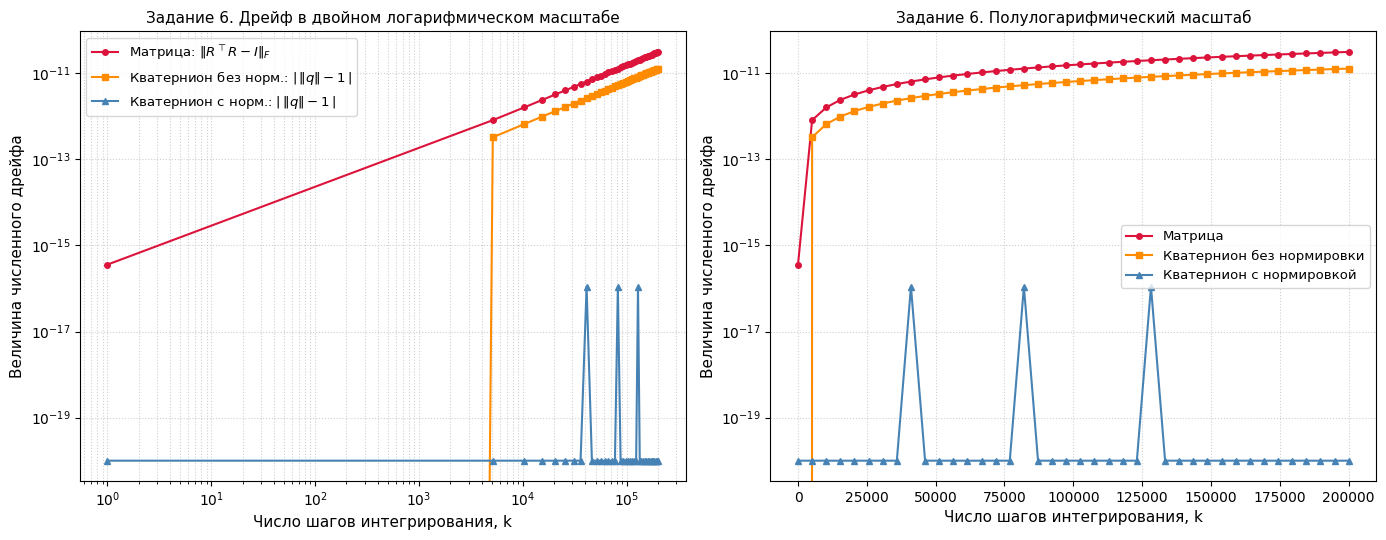

In [ ]:
import time

def quat_mul(a, b):
    """Произведение кватернионов Гамильтона, где q = (w, x, y, z)."""
    aw, ax, ay, az = a
    bw, bx, by, bz = b
    return np.array([
        aw*bw - ax*bx - ay*by - az*bz,
        aw*bx + ax*bw + ay*bz - az*by,
        aw*by - ax*bz + ay*bw + az*bx,
        aw*bz + ax*by - ay*bx + az*bw
    ])

def accumulate_matrix(n_steps, sample_set, R_step):
    """Метод 1: Накопление матрицы поворота R = R * R_step."""
    R = np.eye(3)
    errs = []
    for k in range(1, n_steps + 1):
        R = R @ R_step
        if k in sample_set:
            # Мера дрейфа: отклонение от ортогональности по норме Фробениуса
            errs.append(np.linalg.norm(R.T @ R - np.eye(3), ord='fro'))
    return np.array(errs)

def accumulate_quat_raw(n_steps, sample_set, q_step):
    """Метод 2: Накопление кватерниона без промежуточной нормировки."""
    q = np.array([1.0, 0.0, 0.0, 0.0])
    errs = []
    for k in range(1, n_steps + 1):
        q = quat_mul(q, q_step)
        if k in sample_set:
            # Мера дрейфа: уход модуля кватерниона от единицы
            errs.append(abs(np.linalg.norm(q) - 1.0))
    return np.array(errs)

def accumulate_quat_norm(n_steps, sample_set, q_step):
    """Метод 3: Накопление кватерниона с нормировкой на каждом шаге."""
    q = np.array([1.0, 0.0, 0.0, 0.0])
    errs = []
    for k in range(1, n_steps + 1):
        q = quat_mul(q, q_step)
        q = q / np.linalg.norm(q)
        if k in sample_set:
            errs.append(abs(np.linalg.norm(q) - 1.0))
    return np.array(errs)

# ================================================================= Vatican
# ОСНОВНОЙ БЛОК СИМУЛЯЦИИ И ВИЗУАЛИЗАЦИИ
# ================================================================= Vatican

if __name__ == "__main__":
    print("--- ЗАПУСК ЭКСПЕРИМЕНТА ДЛЯ ЗАДАНИЯ 6 (ЧИСЛЕННЫЙ ДРЕЙФ) ---\n")

    # 1) Задаем параметры интегрирования
    dt = 1e-3
    n_steps = 200000
    n_samples = 40

    # Задаем постоянную угровую скорость вращения твердого тела
    omega_true = np.array([0.7, -0.4, 1.1])
    Omega = np.linalg.norm(omega_true)
    axis = omega_true / Omega
    print(f"Истинная угловая скорость ||omega|| = {Omega:.4f} рад/с, ось = {axis}")

    # Матричный шаг за один дискретный интервал времени dt
    R_step = so3_exp(omega_true * dt)

    # Кватернионный шаг за один интервал dt
    theta_step = Omega * dt
    q_step = np.concatenate(([np.cos(theta_step / 2.0)], np.sin(theta_step / 2.0) * axis))
    q_step /= np.linalg.norm(q_step)

    # Формируем сетку из 40 промежуточных точек для снятия замеров погрешности
    sample_idx = np.linspace(1, n_steps, n_samples).astype(int)
    sample_set = set(sample_idx.tolist())

    # 2) Выполняем симуляцию с замером времени выполнения
    print("\nИнтегрирую систему тремя независимыми способами...")

    t0 = time.perf_counter()
    err_mat = accumulate_matrix(n_steps, sample_set, R_step)
    t1 = time.perf_counter()

    err_q_raw = accumulate_quat_raw(n_steps, sample_set, q_step)
    t2 = time.perf_counter()

    err_q_norm = accumulate_quat_norm(n_steps, sample_set, q_step)
    t3 = time.perf_counter()

    print(f"  * Накопление матрицы завершено за             : {t1 - t0:.3f} сек")
    print(f"  * Накопление сырого кватерниона завершено за  : {t2 - t1:.3f} сек")
    print(f"  * Накопление нормированного кватерниона за    : {t3 - t2:.3f} сек")

    # 3) Вывод финальных результатов в консоль
    print("\nФинальные численные показатели дрейфа (на шаге 200 000):")
    print(f"  - Погрешность матрицы ||R^T * R - I||_F           = {err_mat[-1]:.3e}")
    print(f"  - Погрешность сырого кватерниона ||q|| - 1         = {err_q_raw[-1]:.3e}")
    print(f"  - Погрешность нормированного кватерниона ||q|| - 1  = {err_q_norm[-1]:.3e}")
    print(f"  - Отношение погрешности матрицы к сырому кватерниону: {err_mat[-1] / err_q_raw[-1]:.2f} раз(а)")

    # 4) Построение графиков
    steps_axis = sample_idx.astype(float)

    # Добавляем защитную подложку 1e-20 для нормированного кватерниона, чтобы избежать log(0)
    err_q_norm_safe = np.maximum(err_q_norm, 1e-20)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    # График 1: Двойной логарифмический масштаб (Log-Log)
    axes[0].loglog(steps_axis, err_mat, 'o-', ms=4, lw=1.5, color='crimson', label=r'Матрица: $\|R^\top R - I\|_F$')
    axes[0].loglog(steps_axis, err_q_raw, 's-', ms=4, lw=1.5, color='darkorange', label=r'Кватернион без норм.: $|\,\|q\|-1\,|$')
    axes[0].loglog(steps_axis, err_q_norm_safe, '^-', ms=4, lw=1.5, color='steelblue', label=r'Кватернион с норм.: $|\,\|q\|-1\,|$')
    axes[0].set_xlabel('Число шагов интегрирования, k', fontsize=11)
    axes[0].set_ylabel('Величина численного дрейфа', fontsize=11)
    axes[0].set_title('Задание 6. Дрейф в двойном логарифмическом масштабе', fontsize=11)
    axes[0].grid(True, which='both', linestyle=':', alpha=0.6)
    axes[0].legend(fontsize=9.5)

    # График 2: Полулогарифмический масштаб (Semi-Log)
    axes[1].semilogy(steps_axis, err_mat, 'o-', ms=4, lw=1.5, color='crimson', label='Матрица')
    axes[1].semilogy(steps_axis, err_q_raw, 's-', ms=4, lw=1.5, color='darkorange', label='Кватернион без нормировки')
    axes[1].semilogy(steps_axis, err_q_norm_safe, '^-', ms=4, lw=1.5, color='steelblue', label='Кватернион с нормировкой')
    axes[1].set_xlabel('Число шагов интегрирования, k', fontsize=11)
    axes[1].set_ylabel('Величина численного дрейфа', fontsize=11)
    axes[1].set_title('Задание 6. Полулогарифмический масштаб', fontsize=11)
    axes[1].grid(True, which='both', linestyle=':', alpha=0.6)
    axes[1].legend(fontsize=9.5)

    plt.tight_layout()
    plt.show()

## Задание 7. Цена восстановления: SVD против нормировки

Измерьте время SVD-ортогонализации матрицы и время нормировки кватерниона
(по 20000 повторений каждое).

**Вопрос для вывода:** соедините результат с заданием 6 и сформулируйте, в каких
задачах ориентацию следует хранить кватернионом, а в каких матрицей.

In [ ]:
def orthonormalize_svd(R):
    """
    Восстановление ортогональности матрицы поворота через SVD-разложение.
    Математически находит ближайшую ортогональную матрицу в SO(3).
    """
    R = np.asarray(R, dtype=float)
    U, _, Vt = np.linalg.svd(R)
    R_orth = U @ Vt

    # Если определитель отрицательный (зеркальное отражение),
    # меняем знак последнего столбца матрицы U, чтобы остаться в SO(3)
    if np.linalg.det(R_orth) < 0.0:
        U = U.copy()
        U[:, -1] *= -1.0
        R_orth = U @ Vt
    return R_orth

def normalize_quat(q):
    """Восстановление единичной длины кватерниона q = (w, x, y, z)."""
    q = np.asarray(q, dtype=float)
    return q / np.linalg.norm(q)

# ================================================================= Vatican
# ТЕСТИРОВАНИЕ И ЗАМЕР ПРОИЗВОДИТЕЛЬНОСТИ (ЗАДАНИЕ 7)
# ================================================================= Vatican

if __name__ == "__main__":
    print("--- ЗАПУСК ТЕСТА ПРОИЗВОДИТЕЛЬНОСТИ ДЛЯ ЗАДАНИЯ 7 ---\n")

    rng = np.random.default_rng(42)
    N_REPEATS = 20000

    # 1) Создаем слегка «испорченную» матрицу поворота (с численной погрешностью)
    # Сначала генерируем случайную чистую матрицу через QR-разложение
    A = rng.normal(size=(3, 3))
    Q, _ = np.linalg.qr(A)
    if np.linalg.det(Q) < 0:
        Q[:, -1] *= -1.0
    # Добавляем микрошум, имитирующий дрейф
    R_noisy = Q + 1e-7 * rng.normal(size=(3, 3))

    # 2) Создаем слегка «испорченный» кватернион
    q_random = rng.normal(size=4)
    q_random /= np.linalg.norm(q_random)
    q_noisy = q_random * 1.00005  # делаем его чуть длиннее единицы

    # 3) Замер времени для SVD-ортогонализации матрицы
    print(f"Выполняю {N_REPEATS} повторений SVD-ортогонализации матрицы...")
    t_start_svd = time.perf_counter()
    for _ in range(N_REPEATS):
        _ = orthonormalize_svd(R_noisy)
    t_end_svd = time.perf_counter()
    time_svd_total = t_end_svd - t_start_svd
    time_svd_single_us = (time_svd_total / N_REPEATS) * 1e6  # переводим в микросекунды

    # 4) Замер времени для нормировки кватерниона
    print(f"Выполняю {N_REPEATS} повторений нормировки кватерниона...")
    t_start_quat = time.perf_counter()
    for _ in range(N_REPEATS):
        _ = normalize_quat(q_noisy)
    t_end_quat = time.perf_counter()
    time_quat_total = t_end_quat - t_start_quat
    time_quat_single_us = (time_quat_total / N_REPEATS) * 1e6  # переводим в микросекунды

    # 5) Вывод результатов профилирования
    print("\n[Результаты высокоточных замеров времени]:")
    print(f"  * SVD-ортогонализация матрицы 3x3 : {time_svd_single_us:10.3f} мкс / итерация (всего {time_svd_total:.4f} сек)")
    print(f"  * Нормировка кватерниона 4x1      : {time_quat_single_us:10.3f} мкс / итерация (всего {time_quat_total:.4f} сек)")

    ratio = time_svd_single_us / time_quat_single_us
    print(f"  => Восстановление матрицы через SVD работает в {ratio:.1f} раз(а) МЕДЛЕННЕЕ, чем нормировка кватерниона!")

    # 6) Контроль качества (круговая сверка, что математика отработала корректно)
    R_fixed = orthonormalize_svd(R_noisy)
    q_fixed = normalize_quat(q_noisy)

    err_R = np.linalg.norm(R_fixed.T @ R_fixed - np.eye(3), ord='fro')
    det_R = np.linalg.det(R_fixed)
    err_q = abs(np.linalg.norm(q_fixed) - 1.0)

    print("\n[Контроль качества восстановления]:")
    print(f"  - Отклонение восстановленной матрицы от ортогональности ||R^T * R - I||_F : {err_R:.3e}")
    print(f"  - Определитель восстановленной матрицы det(R)                         : {det_R:.15f}")
    print(f"  - Отклонение модуля кватерниона от единицы | ||q|| - 1 |               : {err_q:.3e}")

--- ЗАПУСК ТЕСТА ПРОИЗВОДИТЕЛЬНОСТИ ДЛЯ ЗАДАНИЯ 7 ---

Выполняю 20000 повторений SVD-ортогонализации матрицы...
Выполняю 20000 повторений нормировки кватерниона...

[Результаты высокоточных замеров времени]:
  * SVD-ортогонализация матрицы 3x3 :     28.391 мкс / итерация (всего 0.5678 сек)
  * Нормировка кватерниона 4x1      :      4.145 мкс / итерация (всего 0.0829 сек)
  => Восстановление матрицы через SVD работает в 6.8 раз(а) МЕДЛЕННЕЕ, чем нормировка кватерниона!

[Контроль качества восстановления]:
  - Отклонение восстановленной матрицы от ортогональности ||R^T * R - I||_F : 1.309e-15
  - Определитель восстановленной матрицы det(R)                         : 1.000000000000001
  - Отклонение модуля кватерниона от единицы | ||q|| - 1 |               : 0.000e+00


## Выводы

_Ответьте на все вопросы, отмеченные в заданиях как «вопрос для вывода», приводя
конкретные числа, которые вы получили._

## Контрольные вопросы

1. Сформулируйте теорему Эйлера о вращении. Как из неё следует, что у поворота три параметра?
2. Выведите формулу Родрига или объясните структуру её слагаемых.
3. Почему в `so3_log` нужно отдельно обрабатывать $\theta \approx 0$ и $\theta \approx \pi$?
4. Что такое двойное накрытие и какие практические затруднения оно создаёт?
5. Почему кватернион задаёт поворот через половинный угол?
6. Что такое gimbal lock? Приведите математическое и механическое объяснение.
7. Почему нельзя интерполировать ориентации покомпонентной интерполяцией углов Эйлера?
8. Почему сумма двух матриц поворота не является матрицей поворота? Как тогда усреднять ориентации?
9. Сравните три представления ориентации по памяти, стоимости композиции и устойчивости.
10. Где в VR-шлеме используется SLERP и что произойдёт при отказе от него?